**Análisis gráfico — Proyecto final de Química Orgánica**


Sustancias: acetaldehído, acetona, benzaldehído, ciclohexanona, butanona, propanaldehído, formaldehído, acetofenona, benzofenona, cinamaldehído

In [73]:
# ANÁLISIS GRÁFICO — Proyecto 5 Química Orgánica
# (Versión corregida: solo cambia la función map_compuesto -> busca el nombre EXACTO)


import re, os, io, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 220,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.facecolor": "white",
})

In [74]:
#1. Carga
try:
    from google.colab import files
    print("Selecciona el archivo Excel de reacciones:")
    up = files.upload()
    df = pd.read_excel(io.BytesIO(list(up.values())[0]))
    EN_COLAB = True
except ImportError:
    df = pd.read_excel("TABLA REACCIONES PROYECTO DE QUIMICA.xlsx")
    EN_COLAB = False

df.columns = [c.strip() for c in df.columns]
os.makedirs("figuras", exist_ok=True)

# Paleta de medios (consistente en todas las figuras)
PAL_MEDIO = {
    "Ácido": "#c0392b",
    "Básico": "#2980b9",
    "Neutro": "#27ae60",
    "Apolar": "#e67e22",
    "No especificado": "#95a5a6",
}

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(f"figuras/{nombre}.png", dpi=220, bbox_inches="tight", facecolor="white")
    plt.show()

Selecciona el archivo Excel de reacciones:


Saving TABLA REACCIONES PROYECTO DE QUIMICA (1).xlsx to TABLA REACCIONES PROYECTO DE QUIMICA (1) (4).xlsx


In [94]:
#2. Limpieza robusta
def sin_tildes(s):
    return "".join(c for c in unicodedata.normalize("NFD", str(s)) if unicodedata.category(c) != "Mn")

SUP = str.maketrans("⁰¹²³⁴⁵⁶⁷⁸⁹⁻", "0123456789-")

def a_num(x):
    """Convierte textos raros de SciFinder / Excel a float."""
    if pd.isna(x):
        return np.nan
    s = str(x).replace("\u200b", "").strip().translate(SUP)
    if s.lower() in ("rt", "ta", "r.t.", "room temp", "temperatura ambiente"):
        return 25.0
    s = re.sub(r"\s+", "", s)
    # notación científica tipo 1,20x10⁵ o 1.20e5
    m = re.match(r"^(-?[\d.,]+)[x×]10([+-]?\d+)$", s, flags=re.I)
    if m:
        return float(m.group(1).replace(",", ".")) * 10 ** int(m.group(2))
    m = re.match(r"^(-?[\d.,]+)[eE]([+-]?\d+)$", s)
    if m:
        return float(m.group(1).replace(",", ".")) * 10 ** int(m.group(2))
    try:
        return float(s.replace(",", "."))
    except ValueError:
        return np.nan

def reescala(v, lo, hi):
    if pd.isna(v):
        return v
    k = 0
    while v > hi and k < 5:
        v /= 10
        k += 1
    return v if lo <= v <= hi else np.nan

# Mapear columnas reales del Excel
COL = {
    "PM_S": "PM (g/mol)",
    "Tf_S": "PF(°C)",
    "Teb_S": "PE (°C)",
    "Dens_S": "D (g/cm³)",
    "pKa_S": "pKa",
    "Dip_S": "MD (D)",
    "Sol_S": "SA (g/L)",
    "Pv_S": "PvT: 298 K (Pa)",
    "PM_P": "Pm (g/mol)2",
    "Tf_P": "Pf(°C)2",
    "Teb_P": "Pe (°C)2",
    "Dens_P": "D (g/cm³)  2",
    "pKa_P": "pKa 2",
    "Dip_P": "Md (D)2",
    "Sol_P": "Sa (g/L) 2",
    "Pv_P": "Pvt: 298 K (Pa) 2",
    "Tr": "Tr (°C)",
    "tmin": "Condicion 1(min)",
    "Medio": "Medio",
    "Tipo": "Tpr",
    "Solvente": "Disolvente",
    "Sustrato": "Sustrato",
    "Producto": "Producto",
    "CAS_S": "NUMERO CAS SUSTRATO",
    "CAS_P": "NUMERO CAS PRODUCTO",
}

# Limpiar nombres de columnas que tienen espacios raros
def encontrar(prefijo):
    for c in df.columns:
        if sin_tildes(c).lower().startswith(sin_tildes(prefijo).lower()[:8]):
            return c
    return None

# Asignar columnas de forma tolerante
for k, v in list(COL.items()):
    if v not in df.columns:
        alt = encontrar(v)
        if alt:
            COL[k] = alt

# Convertir propiedades numéricas
for lado, suf in (("S", "_S"), ("P", "_P")):
    for sig, rng in {
        "PM": (5, 2000), "Tf": (-300, 600), "Teb": (-200, 900),
        "Dens": (0.2, 6), "pKa": (-15, 50), "Dip": (0, 20),
        "Sol": (0, 2e4), "Pv": (0, 1e9)
    }.items():
        col = COL.get(f"{sig}_{lado}")
        if col and col in df.columns:
            serie = df[col].map(a_num)
            if sig in ("PM", "Tf", "Teb", "Dens", "pKa", "Dip"):
                serie = serie.map(lambda z: reescala(z, *rng))
            df[f"{sig}{suf}"] = serie

df["T_rx"] = df[COL["Tr"]].map(a_num) if COL["Tr"] in df.columns else np.nan
df["t_min"] = df[COL["tmin"]].map(a_num) if COL["tmin"] in df.columns else np.nan
df["dPM"] = df["PM_P"] - df["PM_S"]

# Normalizar Medio
def norm_medio(x):
    t = sin_tildes(str(x)).lower()
    if "acid" in t: return "Ácido"
    if "basic" in t: return "Básico"
    if "neutr" in t: return "Neutro"
    if "apolar" in t or "no polar" in t: return "Apolar"
    return "No especificado"

df["Medio_n"] = df[COL["Medio"]].map(norm_medio)

# Normalizar Tipo de reacción (columna Tpr)
def norm_tipo(x):
    t = sin_tildes(str(x)).lower()
    if any(w in t for w in ("oxido-reduc", "redox")): return "Óxido-reducción"
    if "oxid" in t: return "Oxidación"
    if "reduc" in t and "alquil" not in t: return "Reducción"
    if "alquil" in t and "reduc" in t: return "Alquilación reductora"
    if "adic" in t and "nucleofil" in t: return "Adición nucleofílica"
    if "adic" in t and "conjug" in t: return "Adición conjugada"
    if "adic" in t: return "Otras adiciones"
    if "condens" in t: return "Condensación"
    if "acoplam" in t: return "Acoplamiento cruzado"
    if "sustit" in t: return "Sustitución"
    if "hidrol" in t: return "Hidrólisis"
    if any(w in t for w in ("descomp", "ruptura", "fragment", "termica")): return "Descomposición"
    if "olefin" in t or "wittig" in t: return "Olefinación"
    if "cicl" in t: return "Ciclación"
    return "Otras"

df["Tipo_n"] = df[COL["Tipo"]].map(norm_tipo)

# Solvente simplificado
def norm_solvente(x):
    t = sin_tildes(str(x)).lower()
    reglas = [
        ("agua", "Agua"), ("water", "Agua"),
        ("tetrahidrofur", "THF"), ("rofurano", "THF"), ("tetrahydrofur", "THF"),
        ("metanol", "Metanol"), ("methanol", "Metanol"),
        ("etanol", "Etanol"), ("ethanol", "Etanol"),
        ("tolueno", "Tolueno"), ("toluene", "Tolueno"),
        ("diclorometano", "DCM"), ("dichloromethane", "DCM"), ("dcm", "DCM"),
        ("acetonitril", "Acetonitrilo"), ("itril", "Acetonitrilo"),
        ("dimetilformamida", "DMF"), ("dimethylformamide", "DMF"),
        ("benceno", "Benceno"), ("benzene", "Benceno"),
        ("dioxano", "1,4-Dioxano"),
        ("dicloroetano", "1,2-Dicloroetano"),
        ("eter", "Éter"), ("ether", "Éter"),
        ("acetona", "Acetona"),
        ("dmso", "DMSO"), ("sulfoxido", "DMSO"),
    ]
    for clave, nombre in reglas:
        if clave in t:
            return nombre
    if t in ("", "-", "nan", "no aplica", "none"):
        return np.nan
    return "Otros"

df["Solvente_n"] = df[COL["Solvente"]].map(norm_solvente)

# Identificar las 10 sustancias de referencia
BASE = {
    "acetaldehido": "Acetaldehído",
    "acetona": "Acetona",
    "benzaldehido": "Benzaldehído",
    "ciclohexanona": "Ciclohexanona",
    "metil etil cetona": "Butanona",
    "butanona": "Butanona",
    "propanal": "Propanaldehído",
    "propanaldehido": "Propanaldehído",
    "formaldehido": "Formaldehído",
    "acetofenona": "Acetofenona",
    "benzofenona": "Benzofenona",
    "cinamaldehido": "Cinamaldehído",
    "cinnamaldehido": "Cinamaldehído",
}

# >>> CORRECCIÓN: antes buscaba "si el nombre CONTIENE ..." y confundía
# >>> "2-Butanona, 3-bromo-" con butanona o "Propanal, 2-metil-" con propanal.
# >>> Ahora exige que el nombre sea EXACTAMENTE el de la sustancia.
def map_compuesto(x):
    return BASE.get(sin_tildes(str(x)).lower().strip())

df["ref_S"] = df[COL["Sustrato"]].map(map_compuesto)
df["ref_P"] = df[COL["Producto"]].map(map_compuesto)
df["Rol"] = np.where(df["ref_S"].notna(), "Reacción",
                     np.where(df["ref_P"].notna(), "Obtención", "Otro"))
df["Compuesto"] = df["ref_S"].fillna(df["ref_P"])

# Tabla de sustancias únicas (por CAS) para no sesgar correlaciones
cols_prop = ["PM", "Tf", "Teb", "Dens", "pKa", "Dip", "Sol", "Pv"]
S = df[[COL["CAS_S"]] + [f"{c}_S" for c in cols_prop]].copy()
S.columns = ["CAS"] + cols_prop
P = df[[COL["CAS_P"]] + [f"{c}_P" for c in cols_prop]].copy()
P.columns = ["CAS"] + cols_prop
quim = pd.concat([S, P]).drop_duplicates("CAS").dropna(subset=["CAS"]).reset_index(drop=True)

print("=" * 60)
print(f"Filas totales: {len(df)}")
print(f"Reacciones (sustancia = sustrato): {(df.Rol == 'Reacción').sum()}")
print(f"Obtenciones (sustancia = producto): {(df.Rol == 'Obtención').sum()}")
print(f"Sustancias únicas (CAS): {len(quim)}")
print("\nConteo por compuesto y rol:")
print(df.groupby(["Compuesto", "Rol"]).size().unstack(fill_value=0))
print("(Cada sustancia debe tener 10 reacciones y 10 obtenciones)")
print("=" * 60)

Filas totales: 200
Reacciones (sustancia = sustrato): 100
Obtenciones (sustancia = producto): 100
Sustancias únicas (CAS): 195

Conteo por compuesto y rol:
Rol             Obtención  Reacción
Compuesto                          
Acetaldehído           10        10
Acetofenona            10        10
Acetona                10        10
Benzaldehído           10        10
Benzofenona            10        10
Butanona               10        10
Ciclohexanona          10        10
Cinamaldehído          10        10
Formaldehído           10        10
Propanaldehído         10        10
(Cada sustancia debe tener 10 reacciones y 10 obtenciones)


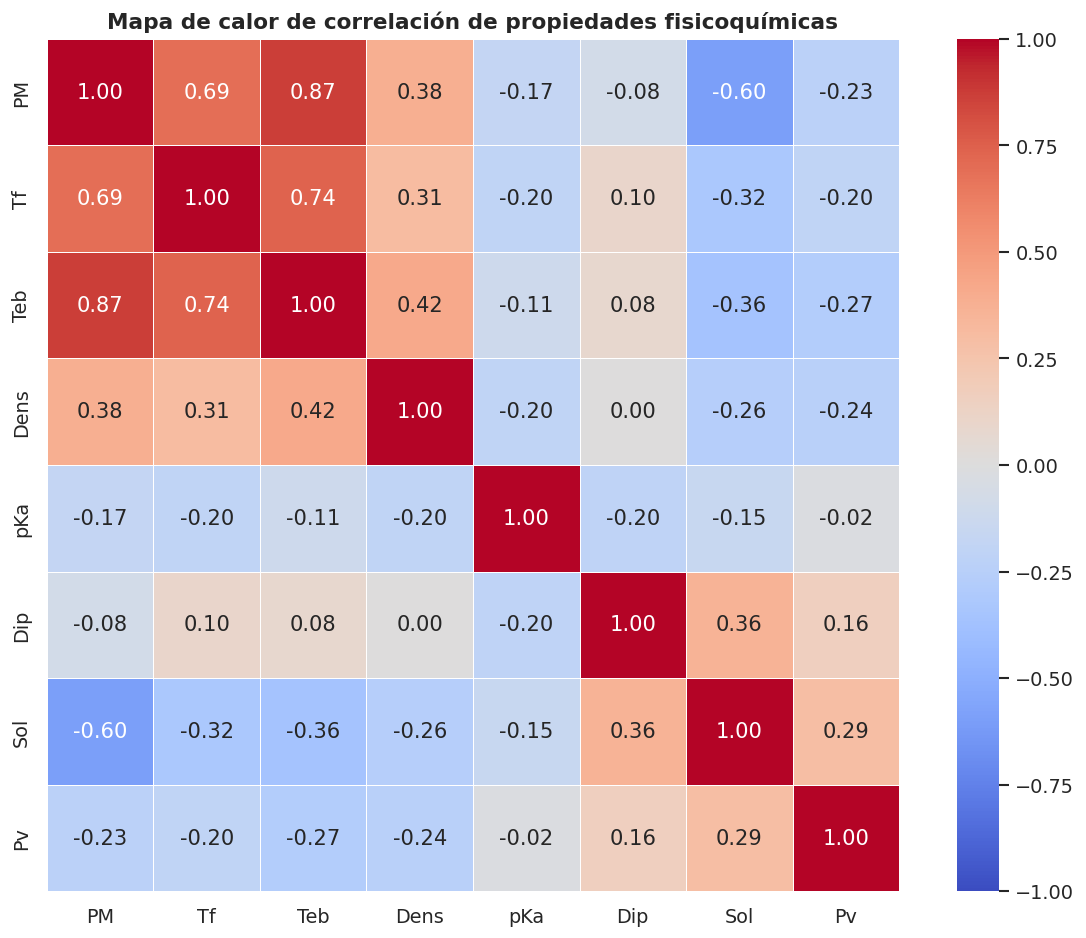

In [95]:

# G1: Mapa de calor de correlación de propiedades fisicoquímicas

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

cols_prop = ["PM", "Tf", "Teb", "Dens", "pKa", "Dip", "Sol", "Pv"]

# Calcular correlaciones
corr = quim[cols_prop].corr(method="pearson", min_periods=5)

#Crear mapa de calor
plt.figure(figsize=(10, 8))

mask = corr.isna()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    mask=mask,
    square=True
)

plt.title("Mapa de calor de correlación de propiedades fisicoquímicas")
plt.tight_layout()

guardar("g01_mapa_calor_propiedades")


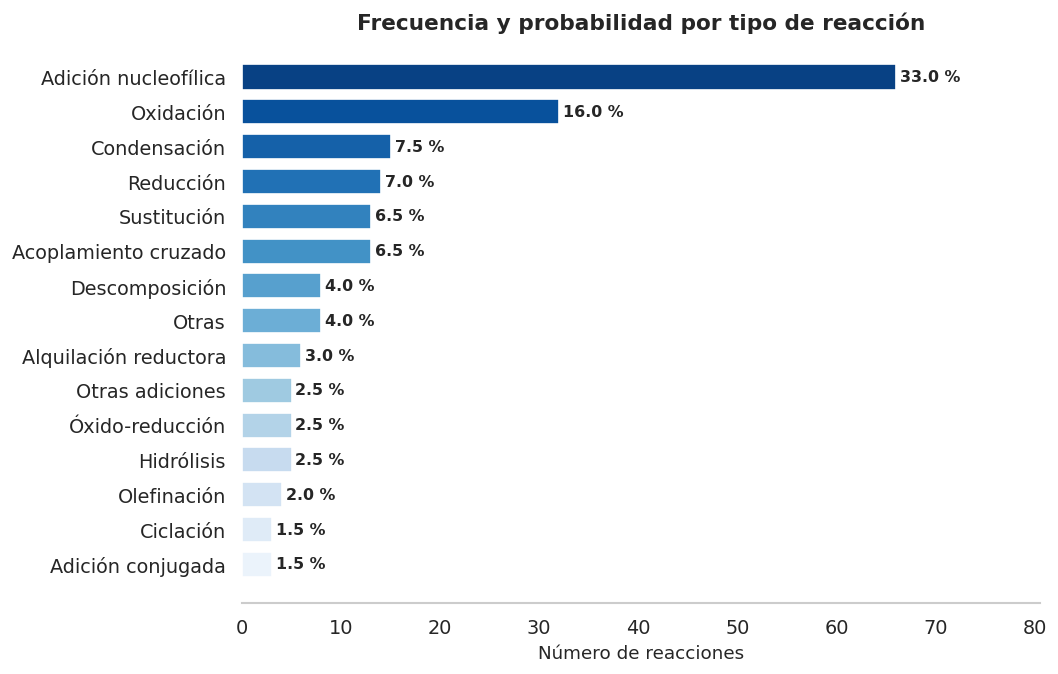

In [77]:


# G1: Frecuencia y probabilidad por tipo de reacción

conteo = df["Tipo_n"].value_counts()
prob = conteo / conteo.sum() * 100

fig, ax = plt.subplots(figsize=(9, 5.8))

colors = sns.color_palette("Blues_r", n_colors=len(conteo))

bars = ax.barh(
    conteo.index,
    conteo.values,
    color=colors,
    edgecolor="white",
    height=0.72
)

for i, (c, p) in enumerate(zip(conteo.values, prob.values)):
    ax.text(
        c + 0.4, i,
        f"{p:.1f} %",
        va="center",
        fontsize=9.5,
        fontweight="bold"
    )

ax.set_xlim(0, conteo.max() * 1.22)
ax.set_xlabel("Número de reacciones")
ax.set_title("Frecuencia y probabilidad por tipo de reacción")
ax.invert_yaxis()

# Quitar todas las cuadrículas
ax.grid(False)

sns.despine(left=True)

guardar("g01_tipo_reaccion")



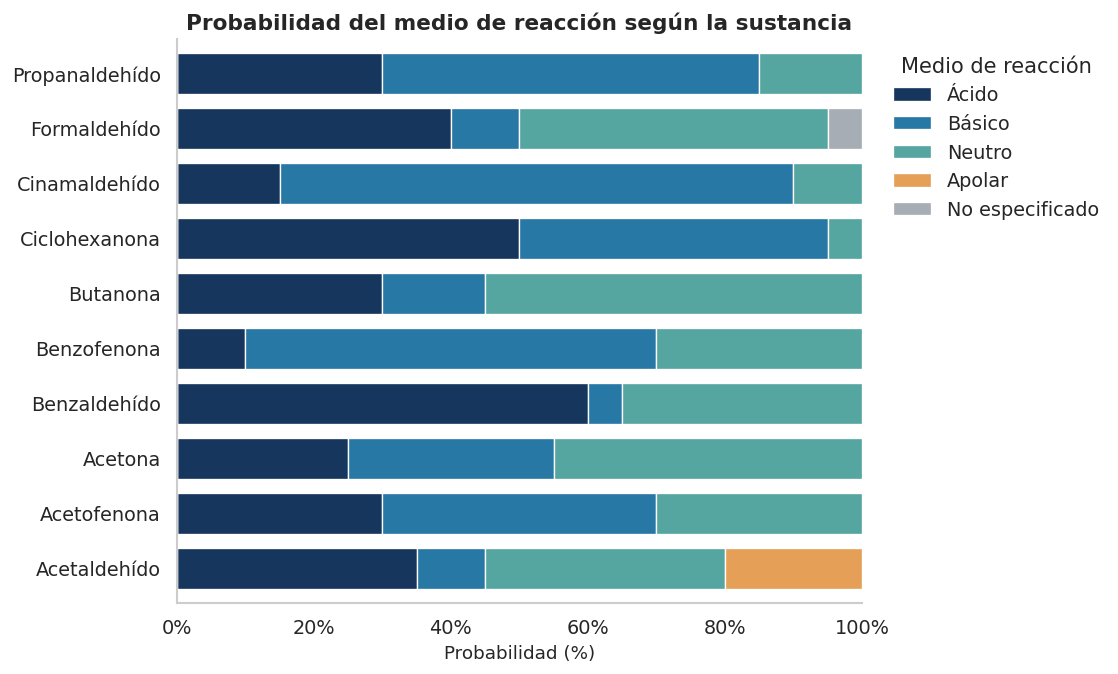

In [78]:

# G2: Probabilidad del medio por sustancia (100 % apilado)

tab = pd.crosstab(
    df["Compuesto"],
    df["Medio_n"],
    normalize="index"
) * 100

orden_m = [
    m for m in ["Ácido", "Básico", "Neutro", "Apolar", "No especificado"]
    if m in tab.columns
]

tab = tab[orden_m].reindex(sorted(tab.index))

# Paleta de colores
PAL_MEDIO = {
    "Ácido": "#17365D",
    "Básico": "#2878A5",
    "Neutro": "#55A6A1",
    "Apolar": "#E69F56",
    "No especificado": "#A6ADB4"
}

fig, ax = plt.subplots(figsize=(9.5, 5.8))

tab.plot(
    kind="barh",
    stacked=True,
    color=[PAL_MEDIO[m] for m in orden_m],
    edgecolor="white",
    linewidth=0.8,
    width=0.75,
    ax=ax
)

ax.set_xlim(0, 100)
ax.set_xlabel("Probabilidad (%)")
ax.set_ylabel("")
ax.set_title("Probabilidad del medio de reacción según la sustancia")

ax.legend(
    title="Medio de reacción",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

ax.xaxis.set_major_formatter(PercentFormatter(100))

# Eliminar todas las cuadrículas
ax.grid(False)

sns.despine()
plt.tight_layout()

guardar("g02_medio_por_sustancia")


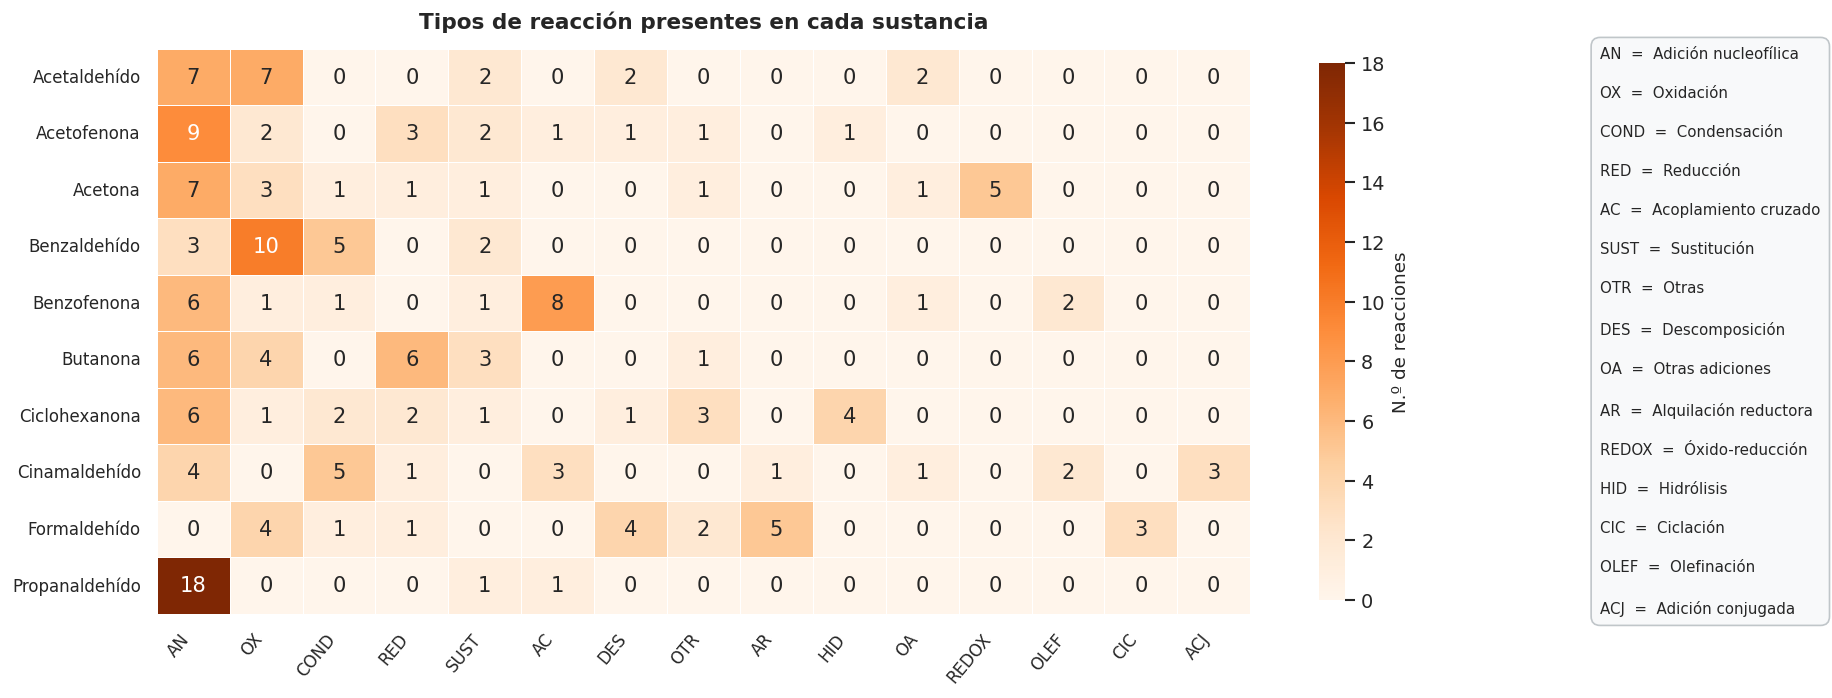

In [79]:
# G03 definitivo: Heatmap limpio y legible
mapa = pd.crosstab(df["Compuesto"], df["Tipo_n"])
mapa = mapa[mapa.sum().sort_values(ascending=False).index]

# Abreviaturas
ABREV = {
    "Adición nucleofílica": "AN",
    "Oxidación": "OX",
    "Condensación": "COND",
    "Reducción": "RED",
    "Acoplamiento cruzado": "AC",
    "Sustitución": "SUST",
    "Otras": "OTR",
    "Descomposición": "DES",
    "Otras adiciones": "OA",
    "Alquilación reductora": "AR",
    "Óxido-reducción": "REDOX",
    "Hidrólisis": "HID",
    "Ciclación": "CIC",
    "Olefinación": "OLEF",
    "Adición conjugada": "ACJ",
}

mapa_corto = mapa.rename(columns=ABREV)

fig, ax = plt.subplots(figsize=(15, 6))

sns.heatmap(
    mapa_corto,
    annot=True,
    fmt="d",
    cmap="Oranges",
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"label": "N.º de reacciones", "shrink": 0.95},
    ax=ax
)

ax.set_title("Tipos de reacción presentes en cada sustancia", pad=12)
ax.set_xlabel("")
ax.set_ylabel("")

# Clave de la legibilidad
ax.set_xticklabels(ax.get_xticklabels(), rotation=50, ha="right", fontsize=10)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=10)

# Leyenda
leyenda_texto = "\n".join([f"{v}  =  {k}" for k, v in ABREV.items() if k in mapa.columns])
props = dict(boxstyle="round,pad=0.6", facecolor="#f8f9fa", edgecolor="#bdc3c7", alpha=0.95)
ax.text(1.32, 0.5, leyenda_texto, transform=ax.transAxes,
        fontsize=9, va="center", ha="left", bbox=props, linespacing=3.00)

# Deja espacio suficiente a la derecha para la leyenda
plt.subplots_adjust(right=0.35, bottom=0.18)
guardar("g03_sustancia_vs_tipo_limpio")

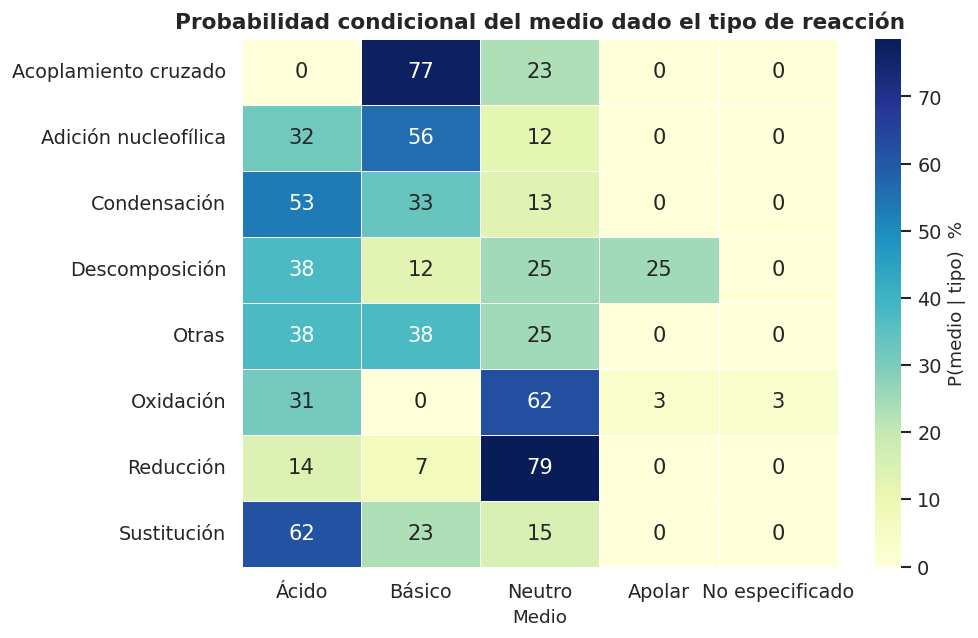

In [80]:
# G4: Probabilidad condicional P(medio | tipo)
tipos_top = df["Tipo_n"].value_counts().index[:8]
cond = pd.crosstab(df[df.Tipo_n.isin(tipos_top)]["Tipo_n"],
                   df["Medio_n"], normalize="index") * 100
cond = cond.reindex(columns=orden_m, fill_value=0)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.heatmap(cond, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=0.5,
            cbar_kws={"label": "P(medio | tipo)  %"}, ax=ax)
ax.set_title("Probabilidad condicional del medio dado el tipo de reacción")
ax.set_xlabel("Medio")
ax.set_ylabel("")
guardar("g04_prob_condicional_medio_tipo")

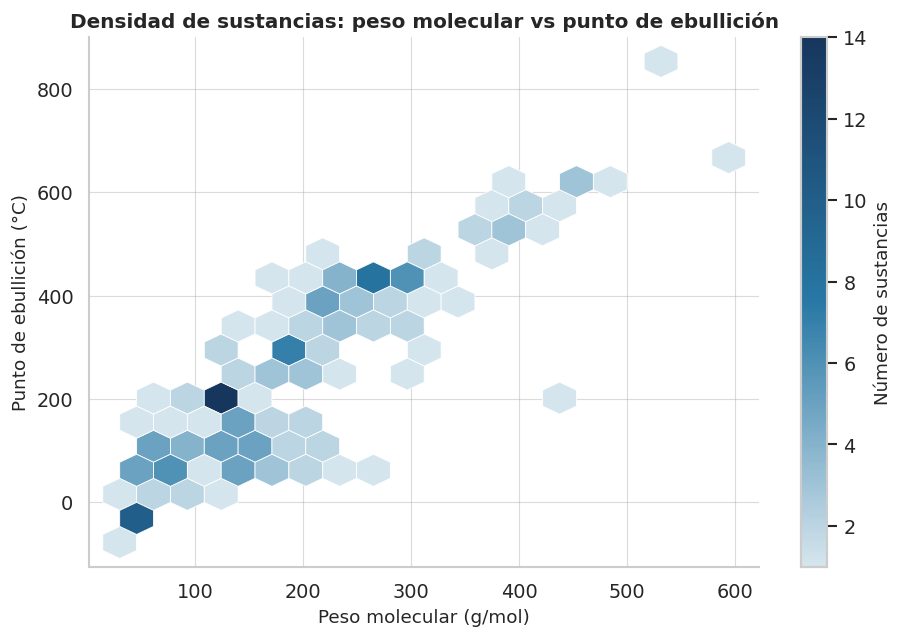

In [81]:




# G5: Peso molecular vs punto de ebullición (Hexbin)

d = quim.dropna(subset=["PM", "Teb"])

fig, ax = plt.subplots(figsize=(8, 5.5))

# Degradado azul científico: claro a oscuro
from matplotlib.colors import LinearSegmentedColormap

azul_cientifico = LinearSegmentedColormap.from_list(
    "azul_cientifico",
    ["#D5E5ED", "#2878A5", "#17365D"]
)

# Gráfico de hexágonos
hb = ax.hexbin(
    d["PM"],
    d["Teb"],
    gridsize=18,
    cmap=azul_cientifico,
    mincnt=1,
    linewidths=0.5,
    edgecolors="white"
)

# Barra de color
cb = fig.colorbar(hb, ax=ax)
cb.set_label("Número de sustancias")

# Título y etiquetas
ax.set_title(
    "Densidad de sustancias: peso molecular vs punto de ebullición",
    fontsize=12,
    fontweight="bold"
)

ax.set_xlabel("Peso molecular (g/mol)")
ax.set_ylabel("Punto de ebullición (°C)")

# Conservar cuadrículas
ax.grid(
    True,
    linestyle="-",
    linewidth=0.7,
    alpha=0.45,
    color="#B0B0B0"
)

sns.despine()
plt.tight_layout()

guardar("g05_pm_vs_teb_hexbin")



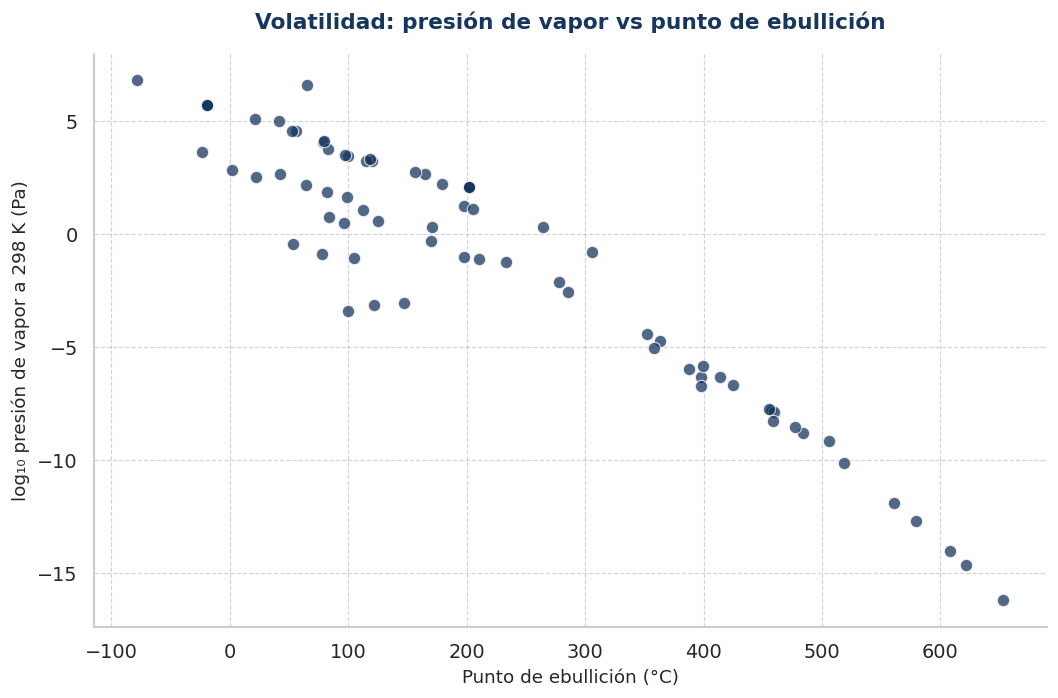

In [82]:




# G6: log Pv vs Teb (volatilidad)

d = quim.dropna(subset=["Teb", "Pv"]).query(
    "Pv > 0"
).assign(logPv=lambda x: np.log10(x.Pv))

fig, ax = plt.subplots(figsize=(9, 6))

# Diagrama de dispersión sin regresión
ax.scatter(
    d["Teb"],
    d["logPv"],
    alpha=0.75,
    s=55,
    color="#17365D",
    edgecolor="white",
    linewidth=0.7
)

# Título
ax.set_title(
    "Volatilidad: presión de vapor vs punto de ebullición",
    fontsize=13,
    fontweight="bold",
    color="#17365D",
    pad=15
)

# Etiquetas
ax.set_xlabel("Punto de ebullición (°C)")
ax.set_ylabel("log₁₀ presión de vapor a 298 K (Pa)")

# Conservar cuadrículas
ax.grid(
    True,
    linestyle="--",
    linewidth=0.7,
    alpha=0.3,
    color="#667085"
)

sns.despine()
plt.tight_layout()

guardar("g06_pv_vs_teb")




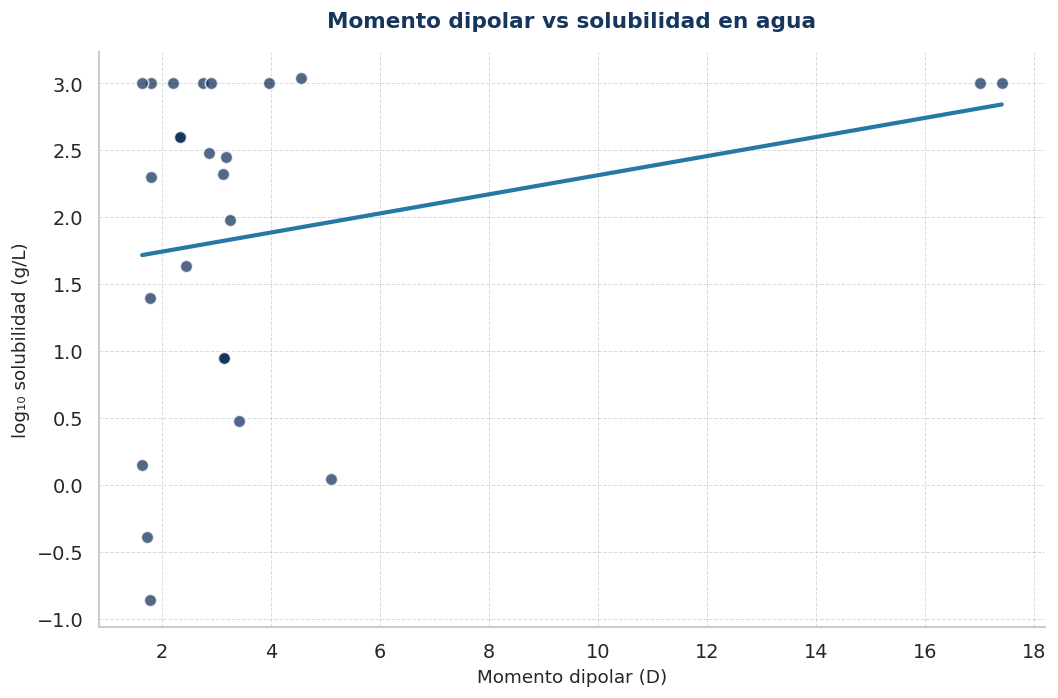

In [83]:
# G7: Dipolo vs log solubilidad

d = quim.dropna(subset=["Dip", "Sol"]).query(
    "Sol > 0"
).assign(logSol=lambda x: np.log10(x.Sol))

fig, ax = plt.subplots(figsize=(9, 6))

sns.regplot(
    data=d,
    x="Dip",
    y="logSol",
    ax=ax,
    ci=None,
    scatter_kws={
        "alpha": 0.75,
        "s": 55,
        "color": "#17365D",
        "edgecolor": "white"
    },
    line_kws={
        "color": "#2878A5",
        "linewidth": 2.5
    }
)

# Título y etiquetas
ax.set_title(
    "Momento dipolar vs solubilidad en agua",
    fontsize=13,
    fontweight="bold",
    color="#17365D",
    pad=15
)

ax.set_xlabel("Momento dipolar (D)")
ax.set_ylabel("log₁₀ solubilidad (g/L)")

# Cuadrícula
ax.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.25,
    color="#667085"
)

sns.despine()
plt.tight_layout()

guardar("g07_dipolo_vs_solubilidad")


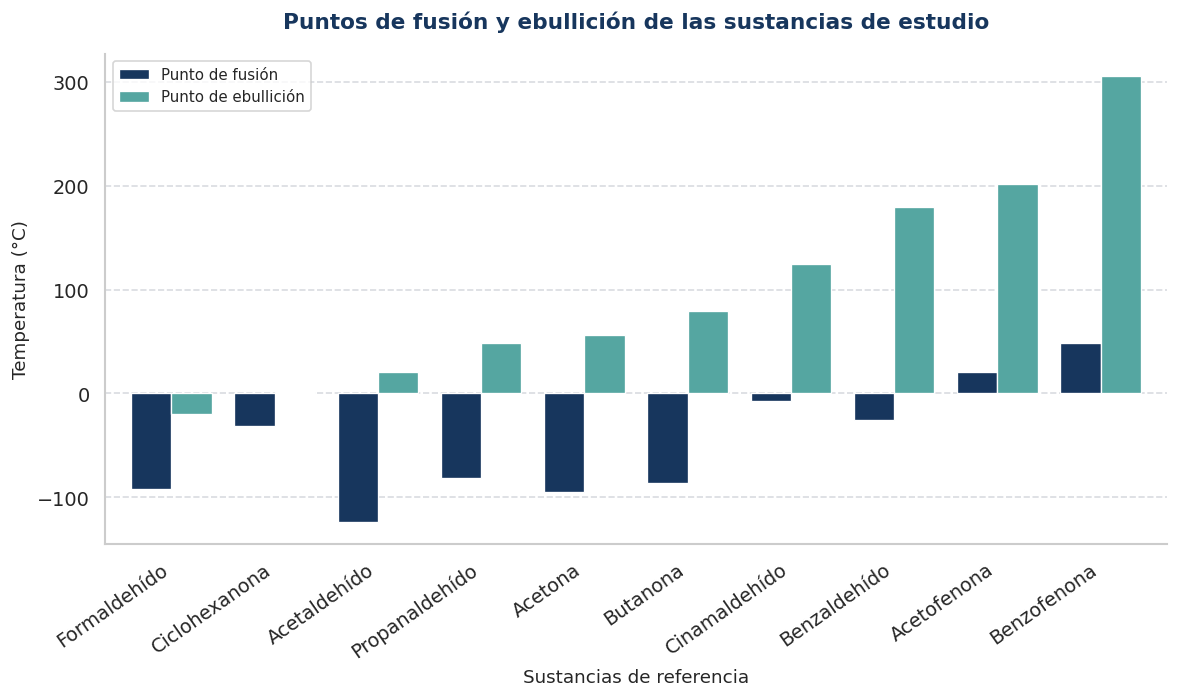

In [84]:

# G8: Tf y Teb de las sustancias de referencia

ref = (df[df.Rol == "Reacción"]
       .groupby("Compuesto")[["Tf_S", "Teb_S"]]
       .median()
       .sort_values("Teb_S"))

ref = ref.rename(columns={
    "Tf_S": "Punto de fusión",
    "Teb_S": "Punto de ebullición"
})

fig, ax = plt.subplots(figsize=(10, 6))

# Barras agrupadas con paleta científica
ref.plot(
    kind="bar",
    ax=ax,
    color=["#17365D", "#55A6A1"],
    width=0.78,
    edgecolor="white",
    linewidth=0.8
)





# Título y etiquetas
ax.set_title(
    "Puntos de fusión y ebullición de las sustancias de estudio",
    fontsize=13,
    fontweight="bold",
    color="#17365D",
    pad=15
)

ax.set_ylabel("Temperatura (°C)")
ax.set_xlabel("Sustancias de referencia")

plt.xticks(rotation=35, ha="right")

ax.legend(
    frameon=True,
    loc="upper left",
    fontsize=9
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25,
    color="#667085"
)
ax.grid(axis="x", visible=False)
sns.despine()
plt.tight_layout()

guardar("g08_tf_teb_referencia")



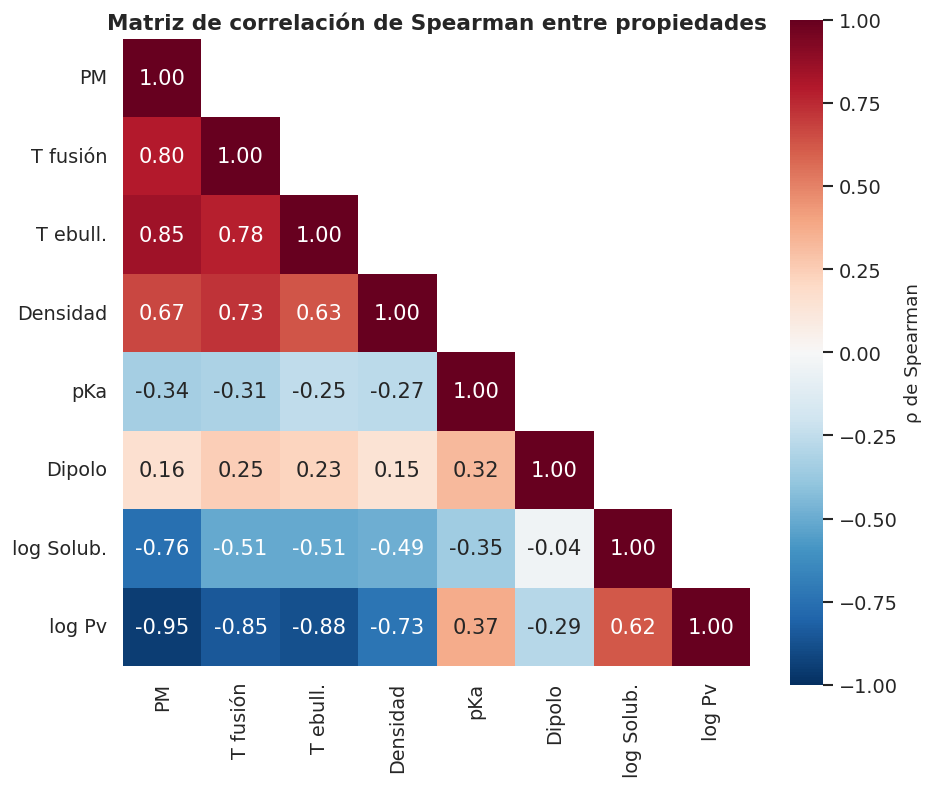

In [90]:
# G9: Matriz de correlación Spearman

c = quim[["PM", "Tf", "Teb", "Dens", "pKa", "Dip", "Sol", "Pv"]].copy()

c["Sol"] = np.log10(c["Sol"].where(c["Sol"] > 0))
c["Pv"] = np.log10(c["Pv"].where(c["Pv"] > 0))

c = c.rename(columns={
    "PM": "PM",
    "Tf": "T fusión",
    "Teb": "T ebull.",
    "Dens": "Densidad",
    "Dip": "Dipolo",
    "Sol": "log Solub.",
    "Pv": "log Pv"
})

corr = c.corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(8, 6.8))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    linewidths=0,
    square=True,
    cbar_kws={"label": "ρ de Spearman"},
    ax=ax
)

ax.set_title("Matriz de correlación de Spearman entre propiedades")

ax.grid(False)

guardar("g09_correlacion")

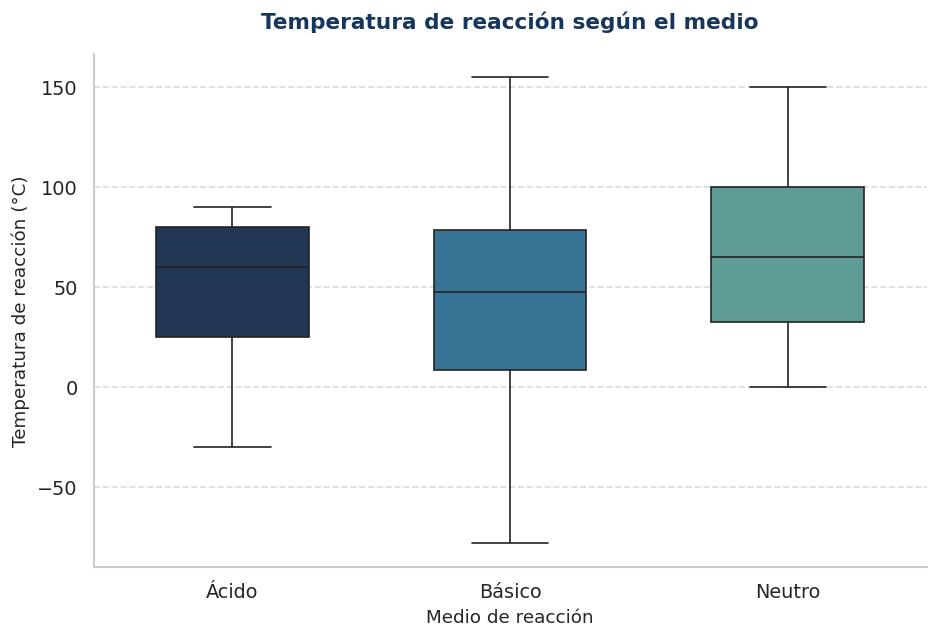

In [96]:

# G10: Temperatura de reacción por medio (Boxplot)

dt = df[
    df.T_rx.between(-80, 350) &
    df.Medio_n.isin(["Ácido", "Básico", "Neutro"])
]

fig, ax = plt.subplots(figsize=(8, 5.5))

# Colores de la paleta científica
PAL_TEMP = {
    "Ácido": "#17365D",
    "Básico": "#2878A5",
    "Neutro": "#55A6A1"
}

sns.boxplot(
    data=dt,
    x="Medio_n",
    y="T_rx",
    hue="Medio_n",
    palette=PAL_TEMP,
    legend=False,
    showmeans=False,
    showfliers=False,
    meanprops=dict(
        marker="D",
        markerfacecolor="white",
        markeredgecolor="#17365D",
        markersize=7
    ),
    order=["Ácido", "Básico", "Neutro"],
    width=0.55,
    ax=ax
)

# Título y etiquetas
ax.set_title(
    "Temperatura de reacción según el medio",
    fontsize=13,
    fontweight="bold",
    color="#17365D",
    pad=15
)

ax.set_xlabel("Medio de reacción")
ax.set_ylabel("Temperatura de reacción (°C)")

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25,
    color="#667085"
)

sns.despine()
plt.tight_layout()

guardar("g10_temp_por_medio")



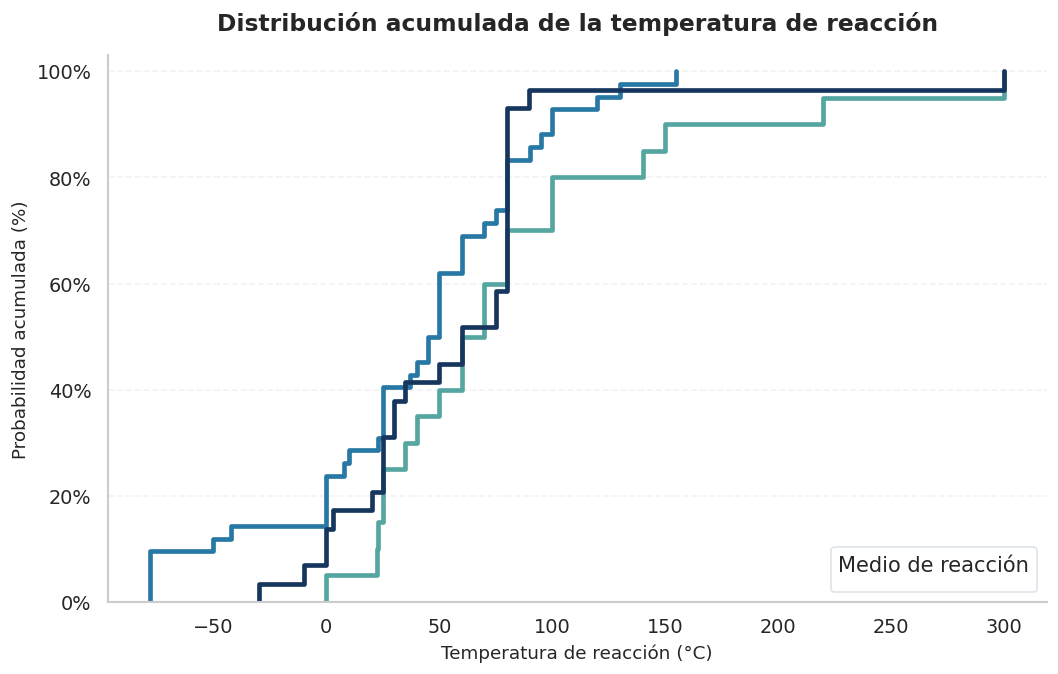

In [92]:

# G11: ECDF de temperatura de reacción por medio

fig, ax = plt.subplots(figsize=(9, 5.8))

# Paleta profesional
pal_ecdf = {
    "Ácido": "#17365D",
    "Básico": "#2878A5",
    "Neutro": "#55A6A1"
}

sns.ecdfplot(
    data=dt,
    x="T_rx",
    hue="Medio_n",
    hue_order=["Ácido", "Básico", "Neutro"],
    palette=pal_ecdf,
    linewidth=2.8,
    ax=ax
)



# Ejes y formato
ax.set_title(
    "Distribución acumulada de la temperatura de reacción",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Temperatura de reacción (°C)", fontsize=11)
ax.set_ylabel("Probabilidad acumulada (%)", fontsize=11)

ax.yaxis.set_major_formatter(
    PercentFormatter(1)
)

ax.set_ylim(0, 1.03)

# Cuadrícula y leyenda
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.grid(axis="x", visible=False)

ax.legend(
    title="Medio de reacción",
    frameon=True,
    facecolor="white",
    edgecolor="#D5DDE5",
    loc="lower right"
)

sns.despine()
plt.tight_layout()

guardar("g11_ecdf_temperatura")


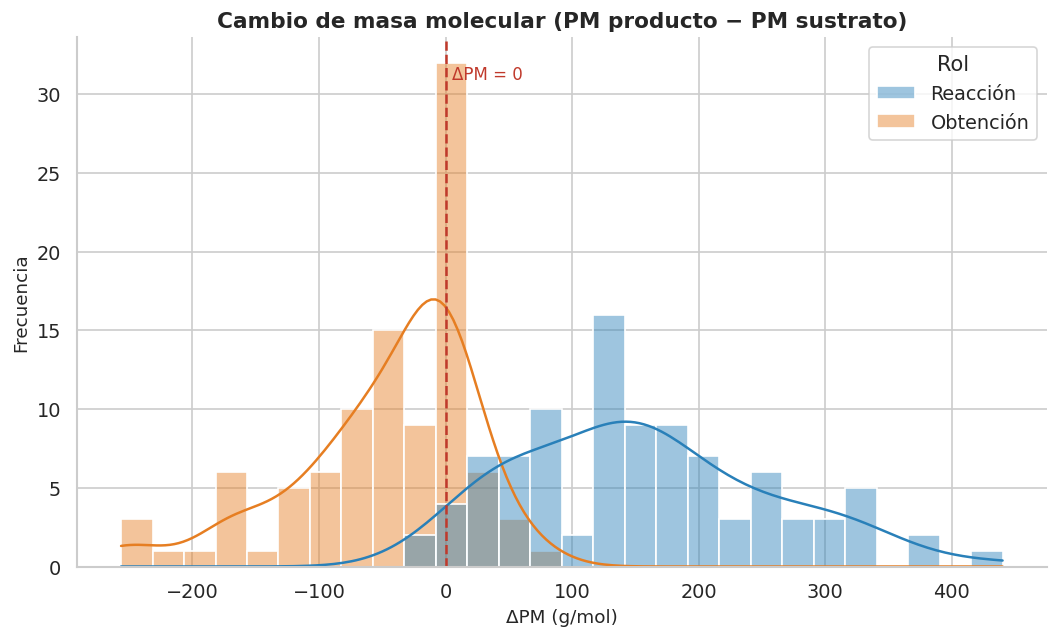

In [88]:
#G12:ΔPM por rol
dd = df[df.dPM.between(-350, 500) & df.Rol.isin(["Reacción", "Obtención"])]
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.histplot(data=dd, x="dPM", hue="Rol", kde=True, bins=28,
             palette={"Reacción": "#2980b9", "Obtención": "#e67e22"},
             alpha=0.45, edgecolor="white", ax=ax)
ax.axvline(0, color="#c0392b", ls="--", lw=1.5)
ax.text(5, ax.get_ylim()[1] * 0.92, "ΔPM = 0", color="#c0392b", fontsize=10)
ax.set_title("Cambio de masa molecular (PM producto − PM sustrato)")
ax.set_xlabel("ΔPM (g/mol)")
ax.set_ylabel("Frecuencia")
sns.despine()
guardar("g12_delta_pm")

In [93]:
#Exportar
df.drop(columns=["ref_S", "ref_P"], errors="ignore").to_csv(
    "tabla_limpia.csv", index=False, encoding="utf-8-sig")
quim.to_csv("sustancias_unicas.csv", index=False, encoding="utf-8-sig")

if EN_COLAB:
    import shutil
    shutil.make_archive("figuras", "zip", "figuras")
    files.download("figuras.zip")
    files.download("tabla_limpia.csv")
    files.download("sustancias_unicas.csv")

print("\n Listo. Figuras en ./figuras/ y datos limpios exportados.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


 Listo. Figuras en ./figuras/ y datos limpios exportados.
